# 03 Contingency tables and goodness of fit: Bangladesh food prices

This notebook covers the BUS173 topics on chi-square tests. The first part asks whether price spikes happen more often in flood months, heavy-rain months and Ramadan months, using 2 x 2 tables. The second part asks whether spikes are spread evenly across the calendar year and whether monthly price changes follow a normal distribution.

Months are not independent draws. A flood lasts several weeks, and a price spike often runs over two months. The chi-square test assumes independent observations, so every 2 x 2 table also gets a block permutation test that keeps the time order (explained in section 2).

Data: national and division prices of the four long-basket staples (rice, wheat flour, lentils, palm oil), 2007 to 2026; flood months from `flood_known` and heavy-rain months from `heavy_rain` (both built by `src/clean.py` from `data/raw/flood_events.csv` and NASA POWER rainfall, read here as they are on disk); Ramadan months from `covariates_monthly`. Results go to `outputs/tables/tests_03_*.csv`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.proportion import proportion_confint
from plot_utils import *
import tests_stats as ts
set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
LONG = ts.LONG
nat = ts.national_wide(LONG)
cov = ts.covariates()
rain = pd.read_parquet(PROC / "rain_division_monthly.parquet")
R, facts = [], []
def fact(name, value, how):
    facts.append({"fact": name, "value": value, "how_computed": how})
    print(f"{name}: {value}")
flood_months = cov.index[cov.flood_known.fillna(False).astype(bool)]
print("flood months on file:", [str(d.date())[:7] for d in flood_months])

flood months on file: ['2004-07', '2004-08', '2004-09', '2007-07', '2007-08', '2007-09', '2017-08', '2019-07', '2020-07', '2020-08', '2022-06', '2024-08']


## 1. Defining a price spike

A **spike month** is a month in which an item's month-on-month log price change is above that item's own 90th percentile over 2007 to 2026. A per-item threshold is needed because palm oil prices move far more than rice prices; one cut-off for all items would make almost every spike a palm oil spike. By construction about 10% of item-months are spikes, so the question is whether that share is higher in flood, heavy-rain or Ramadan months.

The thresholds here use the full 2007 to 2026 sample, which is fine for a descriptive test (palm oil: 4.74%). Notebook 06 uses a different threshold on purpose: it takes the 90th percentile from 2007 to 2019 only (palm oil: 4.22%), so that its out-of-sample backtest does not see future data.

The same rule is applied to each division's own series for the heavy-rain test, because heavy rain is measured by division.

In [2]:
mm = ts.dlog(nat).loc["2007":]
thr = mm.quantile(0.90)
spike = (mm > thr).astype(float).where(mm.notna())
print("90th percentile thresholds, % per month:"); print(thr.round(2))
fact("spike_threshold_rule", "m/m log change > item's 90th percentile, 2007-2026", "Spike definition")
for it in LONG:
    fact(f"spike_threshold_{it}", round(thr[it], 2), "90th percentile of monthly % change")
fact("spike_item_months", int(spike.sum().sum()), "Spike item-months, national, 4 staples")

90th percentile thresholds, % per month:
item
rice_coarse     5.05
atta            4.27
lentil_masur    3.22
palm_oil        4.74
Name: 0.9, dtype: float64
spike_threshold_rule: m/m log change > item's 90th percentile, 2007-2026
spike_threshold_rice_coarse: 5.05
spike_threshold_atta: 4.27
spike_threshold_lentil_masur: 3.22
spike_threshold_palm_oil: 4.74
spike_item_months: 92


## 2. Spikes and events: 2 x 2 tables

For each event the table is event month (yes/no) by spike (yes/no), pooled over the four staples.

- H0: spikes and the event are independent; the spike rate is the same in event months and other months.
- H1: they are associated.

**Tests.**

1. Pearson chi-square test of independence (1 df). It needs expected counts of about 5 or more in every cell.
2. Fisher's exact test, which is exact for small tables. Flood months are rare (a dozen in 20 years), so this is the main test for floods.
3. Effect sizes: Cramer's V (0 = no association, 1 = perfect) and the odds ratio with a Woolf 95% CI.
4. A **circular-shift permutation test**. Both chi-square and Fisher treat the item-months as independent, but the four items are observed in the same months and both spikes and floods come in runs. The permutation test keeps the spike series fixed and rotates the event calendar forward by s months, for every s from 12 to T-12. Each rotation keeps the length and spacing of flood runs but breaks any real link with the spikes. The p-value is the share of rotations whose spike-rate difference is at least as large as the observed one. This is the result to trust when it disagrees with the chi-square.

The flood test is also run with the event moved one month later, because a flood late in a month would show up in prices the month after.

In [3]:
T = mm.index
def event_panel(ev, cols):
    e = pd.Series(ev, index=T).astype(float)
    return np.repeat(e.values[:, None], len(cols), axis=1)
S = spike.values
events = {
    "Flood month (same month)": cov.flood_known.reindex(T).fillna(False).astype(bool),
    "Flood month (prices one month later)": cov.flood_known.shift(1).reindex(T).fillna(False).astype(bool),
    "Ramadan month": cov.ramadan_month.reindex(T).fillna(False).astype(bool),
    "Month before Ramadan": cov.ramadan_month.shift(-1).reindex(T).fillna(False).astype(bool),
}
tables = {}
for name, ev in events.items():
    E = event_panel(ev, LONG)
    ok = ~np.isnan(S)
    t, rows = ts.tests_2x2(E[ok], S[ok], "2 Spikes vs events (national)", name, block_x=E, block_y=S)
    tables[name] = t
    R += rows
    print(name); print(t.rename(index={False: "no event", True: "event"}, columns={False: "no spike", True: "spike"})); print()

Flood month (same month)
y         no spike  spike
x                        
no event       787     88
event           29      4

Flood month (prices one month later)
y         no spike  spike
x                        
no event       791     85
event           25      7

Ramadan month
y         no spike  spike
x                        
no event       740     89
event           76      3

Month before Ramadan
y         no spike  spike
x                        
no event       748     84
event           68      8



### Heavy rain, by division

`heavy_rain` marks a division-month with rainfall above the 90th percentile for that calendar month and division (NASA POWER, 2000 to 2025). It is matched to the same division's price spikes for the six divisions with long price series. This gives many more event months than the flood list, but heavy rain is not the same as a flood.

In [4]:
rows_div, S_cols, E_cols = [], [], []
rain_w = rain.pivot(index="date", columns="division", values="heavy_rain").astype(float)
Tdiv = pd.date_range("2007-01-01", rain.date.max(), freq="MS")
for it in LONG:
    w = ts.division_wide(it)
    d = ts.dlog(w).reindex(Tdiv)
    for dv in d.columns:
        if dv not in rain_w.columns:
            continue
        s = d[dv]
        sp = (s > s.quantile(0.90)).astype(float).where(s.notna())
        S_cols.append(sp.values); E_cols.append(rain_w[dv].reindex(Tdiv).values)
Sd, Ed = np.column_stack(S_cols), np.column_stack(E_cols)
ok = ~np.isnan(Sd) & ~np.isnan(Ed)
t, rows = ts.tests_2x2(Ed[ok], Sd[ok], "2 Spikes vs events (division)", "Heavy-rain month, same division", block_x=Ed, block_y=Sd)
tables["Heavy-rain month, same division"] = t; R += rows
Ed1 = np.vstack([np.full((1, Ed.shape[1]), np.nan), Ed[:-1]])
ok1 = ~np.isnan(Sd) & ~np.isnan(Ed1)
t, rows = ts.tests_2x2(Ed1[ok1], Sd[ok1], "2 Spikes vs events (division)", "Heavy-rain month, prices one month later", block_x=Ed1, block_y=Sd)
tables["Heavy-rain month, prices one month later"] = t; R += rows
print(tables["Heavy-rain month, same division"])
res2 = pd.DataFrame(R)
res2[["data", "test", "n", "statistic", "p", "effect_name", "effect", "ci_low", "ci_high", "conclusion"]].round(3)

y      False  True 
x                  
False   3966    456
True     642     66


,data,test,n,statistic,p,effect_name,effect,ci_low,ci_high,conclusion
0,Flood month (same month),Chi-square independence,908,0.149,0.700,Cramer's V,0.013,NaN,NaN,min expected count 3.3
1,Flood month (same month),Fisher exact,908,NaN,0.766,odds ratio,1.234,0.424,3.590,spike rate 12.1% in event months vs 10.1% othe...
2,Flood month (same month),Circular-shift permutation,908,0.021,0.682,rate difference (pp),2.064,NaN,NaN,event series rotated in time; keeps autocorrel...
3,Flood month (prices one month later),Chi-square independence,908,5.023,0.025,Cramer's V,0.074,NaN,NaN,min expected count 3.2
4,Flood month (prices one month later),Fisher exact,908,NaN,0.035,odds ratio,2.606,1.094,6.204,spike rate 21.9% in event months vs 9.7% other...
5,Flood month (prices one month later),Circular-shift permutation,908,0.122,0.051,rate difference (pp),12.172,NaN,NaN,event series rotated in time; keeps autocorrel...
6,Ramadan month,Chi-square independence,908,3.813,0.051,Cramer's V,0.065,NaN,NaN,min expected count 8.0
7,Ramadan month,Fisher exact,908,NaN,0.051,odds ratio,0.328,0.101,1.062,spike rate 3.8% in event months vs 10.7% other...
8,Ramadan month,Circular-shift permutation,908,-0.069,0.093,rate difference (pp),-6.938,NaN,NaN,event series rotated in time; keeps autocorrel...
9,Month before Ramadan,Chi-square independence,908,0.014,0.905,Cramer's V,0.004,NaN,NaN,min expected count 7.7


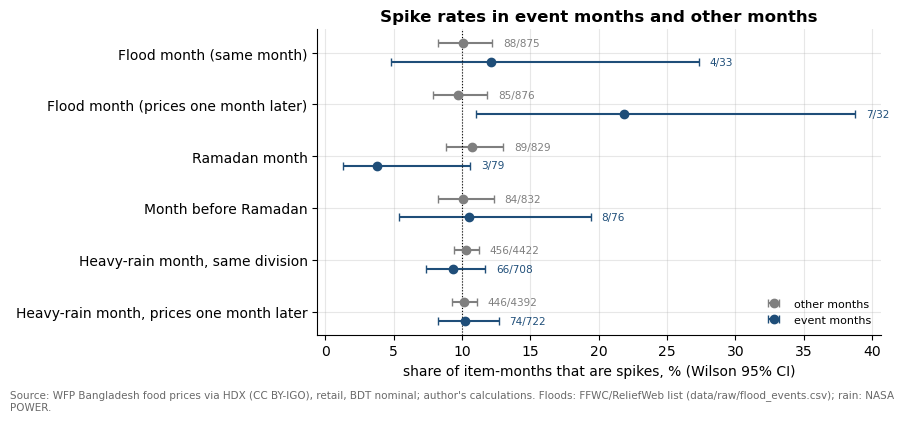

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(tables)
for i, nm in enumerate(names):
    t = tables[nm]
    for j, (ev, col, lab) in enumerate([(False, GREY, "other months"), (True, BLUE, "event months")]):
        k, n = t.loc[ev, True], t.loc[ev].sum()
        lo, hi = proportion_confint(k, n, method="wilson")
        y = i + (0.18 if ev else -0.18)
        ax.errorbar(100 * k / n, y, xerr=[[100 * (k / n - lo)], [100 * (hi - k / n)]], fmt="o", color=col, capsize=3, label=lab if i == 0 else None)
        ax.text(100 * hi + 0.8, y, f"{k}/{n}", va="center", fontsize=7.5, color=col)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.invert_yaxis()
ax.axvline(10, color="black", ls=":", lw=0.8)
ax.set_xlabel("share of item-months that are spikes, % (Wilson 95% CI)")
ax.set_title("Spike rates in event months and other months")
ax.legend(loc="lower right", fontsize=8)
save(fig, "fig13_spike_rates", note=SRC_WFP + " Floods: FFWC/ReliefWeb list (data/raw/flood_events.csv); rain: NASA POWER.")
plt.show()

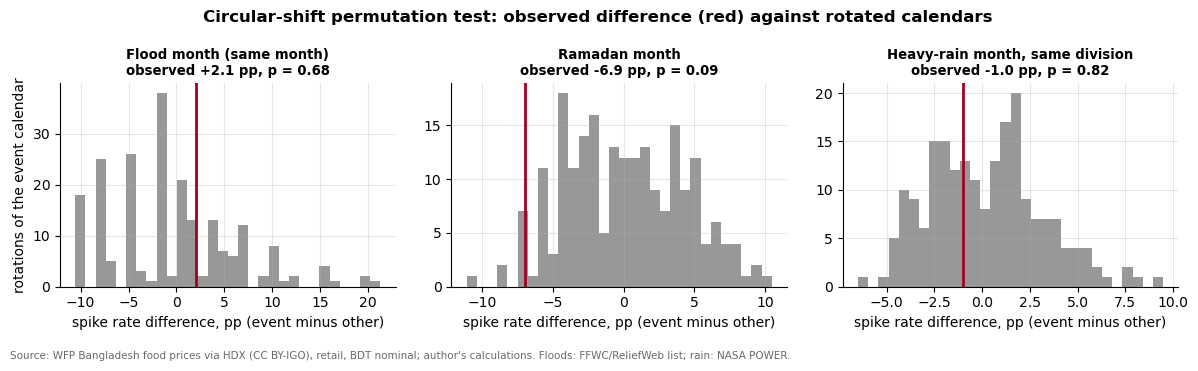

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (nm, S_, E_) in zip(axes, [("Flood month (same month)", S, event_panel(events["Flood month (same month)"], LONG)),
                                     ("Ramadan month", S, event_panel(events["Ramadan month"], LONG)),
                                     ("Heavy-rain month, same division", Sd, Ed)]):
    obs, p, null = ts.circular_shift_test(S_, E_)
    ax.hist(100 * null, bins=30, color=GREY, alpha=0.8)
    ax.axvline(100 * obs, color=RED, lw=2)
    ax.set_title(f"{nm}\nobserved {100*obs:+.1f} pp, p = {p:.2f}", fontsize=9.5)
    ax.set_xlabel("spike rate difference, pp (event minus other)")
axes[0].set_ylabel("rotations of the event calendar")
fig.suptitle("Circular-shift permutation test: observed difference (red) against rotated calendars", fontweight="bold")
save(fig, "fig14_permutation_null", note=SRC_WFP + " Floods: FFWC/ReliefWeb list; rain: NASA POWER.")
plt.show()

In [7]:
res2 = pd.DataFrame(R)
def get(data, test, col):
    return res2[(res2.data == data) & (res2.test == test)][col].iloc[0]
for nm, key in [("Flood month (same month)", "flood"), ("Flood month (prices one month later)", "flood_lag1"), ("Ramadan month", "ramadan"),
                ("Month before Ramadan", "pre_ramadan"), ("Heavy-rain month, same division", "heavy_rain"), ("Heavy-rain month, prices one month later", "heavy_rain_lag1")]:
    t = tables[nm]
    fact(f"spike_rate_{key}_event_pct", round(100 * t.loc[True, True] / t.loc[True].sum(), 1), f"Spike rate in event months, % ({t.loc[True, True]}/{t.loc[True].sum()})")
    fact(f"spike_rate_{key}_other_pct", round(100 * t.loc[False, True] / t.loc[False].sum(), 1), "Spike rate in other months, %")
    fact(f"spike_or_{key}", round(get(nm, "Fisher exact", "effect"), 2), f"Odds ratio, 95% CI {get(nm, 'Fisher exact', 'ci_low'):.2f} to {get(nm, 'Fisher exact', 'ci_high'):.2f}")
    fact(f"spike_p_fisher_{key}", round(get(nm, "Fisher exact", "p"), 3), "Fisher exact p")
    fact(f"spike_p_perm_{key}", round(get(nm, "Circular-shift permutation", "p"), 3), "Circular-shift permutation p")

spike_rate_flood_event_pct: 12.1
spike_rate_flood_other_pct: 10.1
spike_or_flood: 1.23
spike_p_fisher_flood: 0.766
spike_p_perm_flood: 0.682
spike_rate_flood_lag1_event_pct: 21.9
spike_rate_flood_lag1_other_pct: 9.7
spike_or_flood_lag1: 2.61
spike_p_fisher_flood_lag1: 0.035
spike_p_perm_flood_lag1: 0.051
spike_rate_ramadan_event_pct: 3.8
spike_rate_ramadan_other_pct: 10.7
spike_or_ramadan: 0.33
spike_p_fisher_ramadan: 0.051
spike_p_perm_ramadan: 0.093
spike_rate_pre_ramadan_event_pct: 10.5
spike_rate_pre_ramadan_other_pct: 10.1
spike_or_pre_ramadan: 1.05
spike_p_fisher_pre_ramadan: 0.844
spike_p_perm_pre_ramadan: 0.944
spike_rate_heavy_rain_event_pct: 9.3
spike_rate_heavy_rain_other_pct: 10.3
spike_or_heavy_rain: 0.89
spike_p_fisher_heavy_rain: 0.461
spike_p_perm_heavy_rain: 0.82
spike_rate_heavy_rain_lag1_event_pct: 10.2
spike_rate_heavy_rain_lag1_other_pct: 10.2
spike_or_heavy_rain_lag1: 1.01
spike_p_fisher_heavy_rain_lag1: 0.947
spike_p_perm_heavy_rain_lag1: 0.99


## 3. Direction of price change by season (r x c table)

A larger table: each national item-month is classed as **up** (change above +2%), **down** (below -2%) or **flat**, and cross-tabulated against four seasons: winter (Dec to Feb), pre-monsoon (Mar to May), monsoon (Jun to Sep) and post-monsoon (Oct to Nov). The main rice harvests are Aman (Nov-Dec) and Boro (Apr-May).

- H0: direction and season are independent. H1: the direction mix differs by season.

The chi-square test has (3-1)(4-1) = 6 df. Standardised (adjusted) residuals show which cells drive the result: values beyond +/-2 are cells with clearly more or fewer months than independence predicts. The same dependence caveat applies. Rotating by whole years would change nothing here, because seasons repeat every 12 months. So the permutation test shifts each item's direction series by a random 1 to 11 months. That keeps the run structure of the series but moves it out of line with the seasons.

In [8]:
smap = {12: "winter", 1: "winter", 2: "winter", 3: "pre-monsoon", 4: "pre-monsoon", 5: "pre-monsoon", 6: "monsoon", 7: "monsoon", 8: "monsoon", 9: "monsoon", 10: "post-monsoon", 11: "post-monsoon"}
season = pd.Series(T.month.map(smap), index=T)
long = mm.stack().rename("chg").reset_index().rename(columns={"level_0": "date", "level_1": "item"})
long.columns = ["date", "item", "chg"]
long["direction"] = np.select([long.chg > 2, long.chg < -2], ["up", "down"], "flat")
long["season"] = season.reindex(long.date).values
order_s, order_d = ["winter", "pre-monsoon", "monsoon", "post-monsoon"], ["down", "flat", "up"]
ct = pd.crosstab(long.direction, long.season).reindex(index=order_d, columns=order_s)
chi2, p, dof, exp = stats.chi2_contingency(ct.values)
n = ct.values.sum()
rs, cs = ct.sum(1).values[:, None] / n, ct.sum(0).values[None, :] / n
adj = (ct.values - exp) / np.sqrt(exp * (1 - rs) * (1 - cs))
V = ts.cramers_v(ct.values)
# phase-shift permutation: move the direction series 1 to 11 months against the fixed season calendar
rng = np.random.default_rng(ts.RNG_SEED)
dirw = long.pivot(index="date", columns="item", values="direction").reindex(T)
null = []
for _ in range(2000):
    k = rng.integers(1, 12)
    sh = dirw.shift(k)
    l2 = sh.stack().rename("direction").reset_index()
    l2.columns = ["date", "item", "direction"]
    l2["season"] = season.reindex(l2.date).values
    null.append(stats.chi2_contingency(pd.crosstab(l2.direction, l2.season).values)[0])
p_perm = (1 + np.sum(np.array(null) >= chi2)) / (1 + len(null))
R += [ts.row("3 Direction x season", "Chi-square independence", "up/flat/down x season, 4 staples", int(n), chi2, dof, p, "Cramer's V", V,
             conclusion=f"min expected {exp.min():.1f}"),
      ts.row("3 Direction x season", "Phase-shift permutation", "up/flat/down x season, 4 staples", int(n), chi2, np.nan, p_perm, "Cramer's V", V,
             conclusion="direction series shifted 1-11 months; keeps autocorrelation, breaks seasonal alignment")]
print(ct); print(f"chi2 = {chi2:.1f}, df = {dof}, p = {p:.3g}, V = {V:.3f}, permutation p = {p_perm:.3f}")
pd.DataFrame(adj, index=order_d, columns=order_s).round(2)

season     winter  pre-monsoon  monsoon  post-monsoon
direction                                            
down           31           43       46            27
flat          145          144      182            81
up             48           48       75            38
chi2 = 5.3, df = 6, p = 0.51, V = 0.054, permutation p = 0.912


,winter,pre-monsoon,monsoon,post-monsoon
down,-1.10,1.02,-0.58,0.82
flat,1.39,0.18,-0.32,-1.44
up,-0.65,-1.10,0.88,0.94


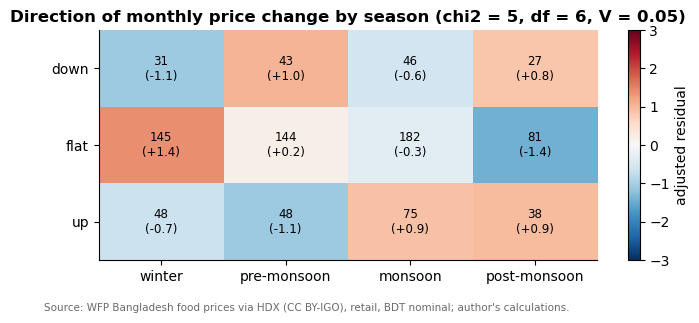

dir_season_chi2: 5.3
dir_season_p_perm: 0.912
dir_season_cramers_v: 0.054


In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
lim = max(3, np.abs(adj).max())
im = ax.imshow(adj, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto"); ax.grid(False)
ax.set_xticks(range(4)); ax.set_xticklabels(order_s); ax.set_yticks(range(3)); ax.set_yticklabels(order_d)
for (i, j), v in np.ndenumerate(adj):
    ax.text(j, i, f"{ct.values[i, j]}\n({v:+.1f})", ha="center", va="center", fontsize=8.5)
fig.colorbar(im, ax=ax, label="adjusted residual")
ax.set_title(f"Direction of monthly price change by season (chi2 = {chi2:.0f}, df = {dof}, V = {V:.2f})")
save(fig, "fig17_direction_season"); plt.show()
fact("dir_season_chi2", round(chi2, 1), f"Chi-square, df {dof}")
fact("dir_season_p_perm", round(p_perm, 3), "Phase-shift permutation p")
fact("dir_season_cramers_v", round(V, 3), "Cramer's V")

## 4. Goodness of fit

### 4a. Are spikes spread evenly over the calendar year?

- H0: a spike is equally likely in every calendar month, so spike counts are proportional to the number of item-months observed in each calendar month.
- H1: some calendar months have more spikes than others.

Chi-square goodness-of-fit test with 11 df. The expected count per month is about 9, above the usual minimum of 5. Spikes in the four items are not independent (they often share a month), which inflates the chi-square statistic, so the test is repeated on months with a spike in **any** item (one count per month, 2007 to 2026).

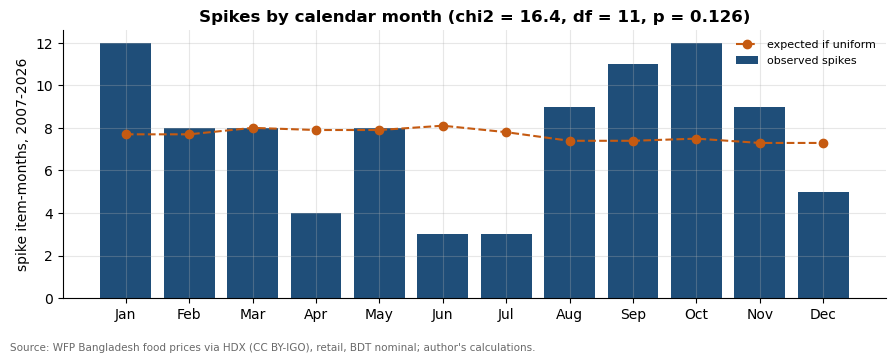

gof_calendar_chi2: 16.4
gof_calendar_p: 0.1256
gof_calendar_any_p: 0.3111
gof_calendar_peak_month: Oct


In [10]:
cal = pd.DataFrame({"spikes": spike.groupby(spike.index.month).sum().sum(axis=1), "obs": spike.notna().groupby(spike.index.month).sum().sum(axis=1)})
exp_c = cal.obs / cal.obs.sum() * cal.spikes.sum()
g1 = stats.chisquare(cal.spikes, exp_c)
anyspk = (spike.max(axis=1) == 1).astype(int)[spike.notna().any(axis=1)]
cal2 = anyspk.groupby(anyspk.index.month).agg(["sum", "size"])
exp2 = cal2["size"] / cal2["size"].sum() * cal2["sum"].sum()
g2 = stats.chisquare(cal2["sum"], exp2)
R += [ts.row("4a Spikes by calendar month", "Chi-square GOF (uniform)", "spike item-months, 4 staples", int(cal.spikes.sum()), g1.statistic, 11, g1.pvalue, "max obs/exp", (cal.spikes / exp_c).max(),
             conclusion=f"min expected {exp_c.min():.1f}; item spikes in the same month are not independent"),
      ts.row("4a Spikes by calendar month", "Chi-square GOF (uniform)", "months with a spike in any staple", int(cal2['sum'].sum()), g2.statistic, 11, g2.pvalue, "max obs/exp", (cal2['sum'] / exp2).max(),
             conclusion=f"min expected {exp2.min():.1f}")]
fig, ax = plt.subplots(figsize=(9, 3.6))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.bar(range(12), cal.spikes.values, color=BLUE, label="observed spikes")
ax.plot(range(12), exp_c.values, "o--", color=ORANGE, label="expected if uniform")
ax.set_xticks(range(12)); ax.set_xticklabels(months)
ax.set_ylabel("spike item-months, 2007-2026")
ax.set_title(f"Spikes by calendar month (chi2 = {g1.statistic:.1f}, df = 11, p = {g1.pvalue:.3f})")
ax.legend(fontsize=8)
save(fig, "fig15_spikes_calendar"); plt.show()
fact("gof_calendar_chi2", round(g1.statistic, 1), "Chi-square GOF, spike item-months by calendar month, df 11")
fact("gof_calendar_p", round(g1.pvalue, 4), "p-value")
fact("gof_calendar_any_p", round(g2.pvalue, 4), "p-value, months with a spike in any staple")
fact("gof_calendar_peak_month", months[int(np.argmax(cal.spikes.values / exp_c.values))], "Calendar month with the highest observed/expected ratio")

### 4b. Are monthly price changes normal?

Many textbook methods (t-intervals for single months, the usual value-at-risk rule of thumb, control charts) assume normal changes. Food prices tend to have fat tails: long quiet stretches and a few large jumps.

- H0: monthly % changes of each item come from a normal distribution. H1: they do not.

Tests: Shapiro-Wilk; the Kolmogorov-Smirnov test with estimated mean and SD (the Lilliefors version, because the plain KS p-value is wrong when the parameters come from the same data); Jarque-Bera, which looks at skewness and kurtosis directly. Then a Student t distribution is fitted by maximum likelihood and the two fits compared by AIC (lower is better). A KS test against the fitted t is reported as a rough check only; its p-value is too generous because the t parameters were estimated from the same data. Months are treated as independent here; the mild autocorrelation in monthly changes does not change the conclusion about tails.

A Benford first-digit test is not run. Benford's law needs data that span several orders of magnitude, and a single item's price moves within a factor of three or four over 20 years, so its first digits would fail Benford for reasons that have nothing to do with data quality.

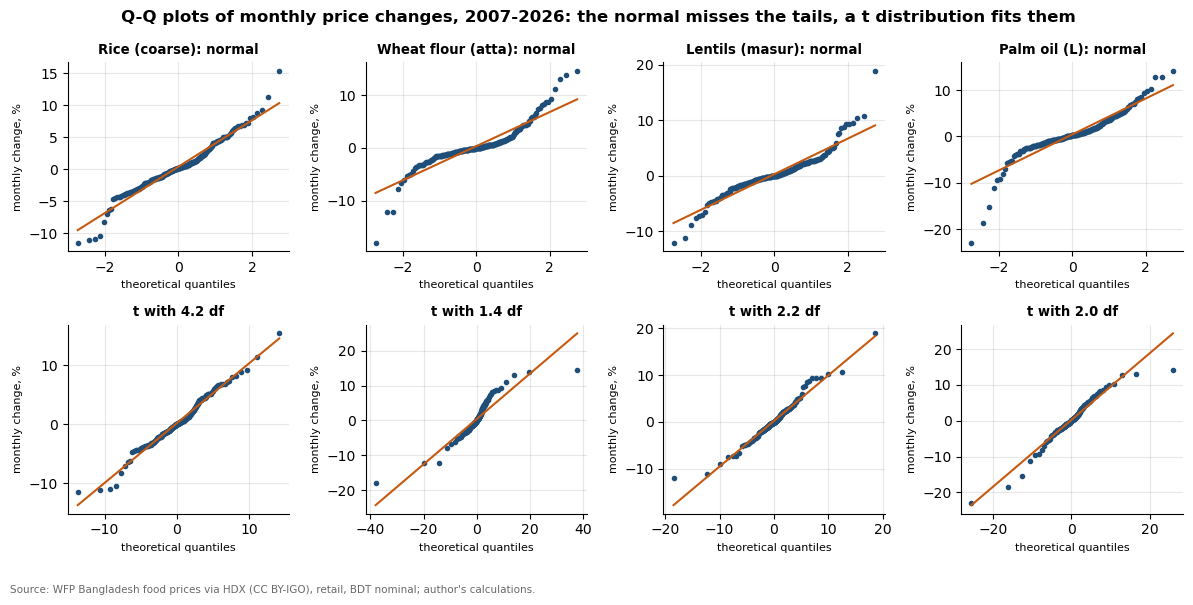

kurtosis_rice_coarse: 1.92
t_df_rice_coarse: 4.2
aic_gain_t_rice_coarse: 15.6
beyond3sd_rice_coarse_pct: 1.8
kurtosis_atta: 6.52
t_df_atta: 1.4
aic_gain_t_atta: 127.5
beyond3sd_atta_pct: 3.1
kurtosis_lentil_masur: 5.64
t_df_lentil_masur: 2.2
aic_gain_t_lentil_masur: 68.9
beyond3sd_lentil_masur_pct: 1.7
kurtosis_palm_oil: 7.27
t_df_palm_oil: 2.0
aic_gain_t_palm_oil: 86.1
beyond3sd_palm_oil_pct: 2.2


,item,n,mean,sd,skew,excess_kurtosis,shapiro_p,lilliefors_p,jb_p,t_df,aic_normal,aic_t,ks_t_p,share_beyond_3sd,normal_share_beyond_3sd
0,rice_coarse,226,0.398,3.662,0.159,1.919,0.0,0.001,0.0,4.204,1231.058,1215.450,0.372,0.018,0.003
1,atta,229,0.332,3.508,0.162,6.523,0.0,0.001,0.0,1.377,1227.627,1100.092,0.372,0.031,0.003
2,lentil_masur,229,0.264,3.370,0.766,5.641,0.0,0.001,0.0,2.248,1209.323,1140.466,0.645,0.017,0.003
3,palm_oil,224,0.426,4.157,-1.003,7.266,0.0,0.001,0.0,1.966,1276.941,1190.857,0.390,0.022,0.003


In [11]:
fit_rows = []
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, it in enumerate(LONG):
    x = mm[it].dropna().values
    sh = stats.shapiro(x); lks, lp = lilliefors(x, dist="norm"); jb = stats.jarque_bera(x)
    df_t, loc_t, sc_t = stats.t.fit(x)
    ll_n = stats.norm.logpdf(x, x.mean(), x.std(ddof=0)).sum()
    ll_t = stats.t.logpdf(x, df_t, loc_t, sc_t).sum()
    aic_n, aic_t = 4 - 2 * ll_n, 6 - 2 * ll_t
    kst = stats.kstest(x, "t", args=(df_t, loc_t, sc_t))
    ex = stats.kurtosis(x)
    sec = "4b Normality of monthly changes"
    R += [ts.row(sec, "Shapiro-Wilk", it, len(x), sh.statistic, np.nan, sh.pvalue, "excess kurtosis", ex, conclusion="not normal" if sh.pvalue < 0.05 else "normal not rejected"),
          ts.row(sec, "Lilliefors (KS, estimated parameters)", it, len(x), lks, np.nan, lp, "skewness", stats.skew(x)),
          ts.row(sec, "Jarque-Bera", it, len(x), jb.statistic, 2, jb.pvalue, "excess kurtosis", ex),
          ts.row(sec, "KS vs fitted t (rough)", it, len(x), kst.statistic, np.nan, kst.pvalue, "t degrees of freedom", df_t,
                 conclusion=f"AIC normal {aic_n:.1f}, t {aic_t:.1f}: " + ("t fits better" if aic_t < aic_n - 2 else "no clear gain"))]
    fit_rows.append(dict(item=it, n=len(x), mean=x.mean(), sd=x.std(ddof=1), skew=stats.skew(x), excess_kurtosis=ex, shapiro_p=sh.pvalue, lilliefors_p=lp, jb_p=jb.pvalue,
                         t_df=df_t, aic_normal=aic_n, aic_t=aic_t, ks_t_p=kst.pvalue,
                         share_beyond_3sd=np.mean(np.abs(x - x.mean()) > 3 * x.std(ddof=1)), normal_share_beyond_3sd=2 * stats.norm.sf(3)))
    stats.probplot(x, dist="norm", plot=axes[0, j]); axes[0, j].set_title(f"{ITEM_LABEL[it]}: normal", fontsize=9.5)
    stats.probplot(x, dist=stats.t, sparams=(df_t, loc_t, sc_t), plot=axes[1, j]); axes[1, j].set_title(f"t with {df_t:.1f} df", fontsize=9.5)
    for a in axes[:, j]:
        a.get_lines()[0].set(color=BLUE, markersize=3); a.get_lines()[1].set(color=ORANGE)
        a.set_xlabel("theoretical quantiles", fontsize=8); a.set_ylabel("monthly change, %", fontsize=8)
fig.suptitle("Q-Q plots of monthly price changes, 2007-2026: the normal misses the tails, a t distribution fits them", fontweight="bold")
save(fig, "fig16_qq_monthly_changes"); plt.show()
fits = pd.DataFrame(fit_rows)
fits.to_csv(TAB / "tests_03_distribution_fit.csv", index=False)
for _, r in fits.iterrows():
    fact(f"kurtosis_{r['item']}", round(r.excess_kurtosis, 2), "Excess kurtosis of monthly % change (normal = 0)")
    fact(f"t_df_{r['item']}", round(r.t_df, 1), "Fitted t degrees of freedom")
    fact(f"aic_gain_t_{r['item']}", round(r.aic_normal - r.aic_t, 1), "AIC(normal) - AIC(t); positive favours t")
    fact(f"beyond3sd_{r['item']}_pct", round(100 * r.share_beyond_3sd, 1), "Share of months beyond 3 SD, % (normal: 0.27%)")
fits.round(3)

## 5. All results and the multiple-testing correction

Holm's correction is applied within each section, as in notebook 02.

In [12]:
res = ts.holm(pd.DataFrame(R), family="section")
res["reject_5pct"] = res.p < 0.05
res["reject_holm"] = res.p_holm < 0.05
res.to_csv(TAB / "tests_03_contingency_gof.csv", index=False)
pd.concat({k: v.stack() for k, v in tables.items()}).rename("count").reset_index().rename(columns={"level_0": "event", "x": "event_month", "y": "spike"}).to_csv(TAB / "tests_03_crosstabs.csv", index=False)
fact("tests_03_total", int(res.p.notna().sum()), "Tests with a p-value in notebook 03")
fact("tests_03_reject_raw", int(res.reject_5pct.sum()), "p < 0.05 before correction")
fact("tests_03_reject_holm", int(res.reject_holm.sum()), "p < 0.05 after Holm within section")
ts.write_facts(facts, "03")
res[["section", "test", "data", "n", "statistic", "df", "p", "p_holm", "effect_name", "effect", "ci_low", "ci_high"]].round(4)

tests_03_total: 38
tests_03_reject_raw: 14
tests_03_reject_holm: 12


,section,test,data,n,statistic,df,p,p_holm,effect_name,effect,ci_low,ci_high
0,2 Spikes vs events (national),Chi-square independence,Flood month (same month),908,0.1488,1.0,0.6997,1.0000,Cramer's V,0.0128,NaN,NaN
1,2 Spikes vs events (national),Fisher exact,Flood month (same month),908,NaN,NaN,0.7661,1.0000,odds ratio,1.2335,0.4238,3.5904
2,2 Spikes vs events (national),Circular-shift permutation,Flood month (same month),908,0.0206,NaN,0.6822,1.0000,rate difference (pp),2.0641,NaN,NaN
3,2 Spikes vs events (national),Chi-square independence,Flood month (prices one month later),908,5.0231,1.0,0.0250,0.3001,Cramer's V,0.0744,NaN,NaN
4,2 Spikes vs events (national),Fisher exact,Flood month (prices one month later),908,NaN,NaN,0.0353,0.3887,odds ratio,2.6056,1.0944,6.2038
5,2 Spikes vs events (national),Circular-shift permutation,Flood month (prices one month later),908,0.1217,NaN,0.0514,0.5082,rate difference (pp),12.1718,NaN,NaN
6,2 Spikes vs events (national),Chi-square independence,Ramadan month,908,3.8133,1.0,0.0508,0.5082,Cramer's V,0.0648,NaN,NaN
7,2 Spikes vs events (national),Fisher exact,Ramadan month,908,NaN,NaN,0.0508,0.5082,odds ratio,0.3282,0.1014,1.0622
8,2 Spikes vs events (national),Circular-shift permutation,Ramadan month,908,-0.0694,NaN,0.0935,0.6542,rate difference (pp),-6.9384,NaN,NaN
9,2 Spikes vs events (national),Chi-square independence,Month before Ramadan,908,0.0142,1.0,0.9053,1.0000,Cramer's V,0.0039,NaN,NaN


## What the tests say

Numbers below come from `tests_03_contingency_gof.csv` and `key_facts_tests.csv` for this run.

- **Floods.** In the flood month itself, spikes are about as common as in other months (12.1% vs 10.1%; odds ratio 1.23, 95% CI 0.42 to 3.59; Fisher p = 0.77). The month after a flood looks different: 7 of 32 item-months (21.9%) are spikes against 9.7% otherwise, an odds ratio of 2.6 (CI 1.1 to 6.2, Fisher p = 0.035). The permutation test, which allows for floods and spikes coming in runs, gives p = 0.05, and the result does not survive Holm. With only a handful of flood events, this is a lead worth checking against more years of data, not a finding.
- **Heavy rain.** Division-months with heavy rain have no more spikes than other months, in the same month or the month after (odds ratios 0.89 and 1.01, all p > 0.4). A rainy month is not a flood, and most heavy-rain months do not disrupt markets enough to move prices.
- **Ramadan.** Spikes are, if anything, rarer in Ramadan months (3.8% vs 10.7%, odds ratio 0.33, Fisher p = 0.051, permutation p = 0.09). The month before Ramadan has the normal rate. This matches notebook 02: no Ramadan price surge in the national series.
- **Season.** The mix of up, flat and down months is about the same in all four seasons (chi-square 5.3 on 6 df, p = 0.51, Cramer's V = 0.05).
- **Calendar months.** Spikes are not clearly concentrated in any calendar month (chi-square GOF p = 0.13; p = 0.31 when counting each month once). October has the most spikes relative to expectation.
- **Distribution.** Monthly changes are not normal for any staple. All three normality tests reject, and excess kurtosis runs from 1.9 for rice to 7.3 for palm oil. Between 1.7% and 3.1% of months lie more than 3 SD from the mean, against 0.27% under a normal. A t distribution fits much better by AIC, with 1.4 to 4.2 degrees of freedom. In practice, a normal-based rule such as "a 3-SD move happens once in 30 years" understates how often large price jumps happen by a factor of about ten.
- **Multiple testing.** 14 of 38 p-values are below 0.05, and 12 survive Holm. All 12 are normality tests. None of the event associations survives.